# CS-13410 Introduction to Machine Learning — Semester Project
Part 1: Data Preparation & Leakage-Free Pipeline · Part 2: Supervised Learning Baseline
**Dataset:** IBM Telco Customer Churn (7,043 customers × 21 columns)
**Group members:** Syed Ahmad Ali (70147064), Umair Sajjid (70146750), Jawad Raza (70146212)

This is the group's single evolving notebook. Part 1 is the first section of the group's evolving project notebook. Later parts (models, ensembles, neural network, clustering) will reuse the `preprocessor` built here.

## 1.1 Problem Framing

| Item | Decision |
|---|---|
| **Prediction target** | `Churn` — did the customer leave the company in the last month? (Yes / No) |
| **Task type** | Binary **classification** (supervised) |
| **Primary success metric** | **ROC-AUC** — measures how well the model ranks churners above non-churners, independent of a decision threshold |
| **Secondary metric** | **F1-score of the churn class** (and recall) — the business cares most about *catching* churners so retention offers can be sent |
| **Why not accuracy?** | Only ~26% of customers churn. A model that predicts "No" for everyone already scores ~73% accuracy while being useless. |

**Business value:** acquiring a new customer costs far more than keeping one. If the telecom company can predict who is likely to leave, it can target them with discounts or support before they cancel.

## 1.2 Setup and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn import set_config

set_config(display="diagram")          # shows the pipeline as a diagram
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42                       # fixed seed -> reproducible results

In [2]:
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
try:
    df = pd.read_csv("Telco-Customer-Churn.csv")     # local copy in the repo
except FileNotFoundError:
    df = pd.read_csv(URL)                            # fallback: download
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.3 Data Understanding

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Observation:** `TotalCharges` should be numeric but pandas read it as `object` (text). That usually means some cells contain non-numeric values. Let's check.

In [4]:
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum())
df.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


All 11 blank rows have `tenure = 0` — they are brand-new customers who have not been billed yet. The value is **missing**, not zero-by-error. We convert the column to numeric (blanks → `NaN`) and let the **imputer inside the pipeline** fill them later.

> Converting a data type is a *stateless* fix (it doesn't learn anything from the data), so it is safe to do before splitting. Filling the NaN with a median **is** learned from data, so that must happen inside the pipeline.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# customerID is a unique identifier: it carries no predictive signal and would
# only let a model memorise rows, so we drop it.
df = df.drop(columns="customerID")

# Encode the target as 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Duplicate rows:", df.duplicated().sum())
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

Duplicate rows: 22
Missing values per column:
TotalCharges    11
dtype: int64


**Duplicates:** after removing `customerID`, 22 rows look identical. Checking them shows they are all customers with `tenure = 1` on the same basic plan — i.e. **different real customers** who happen to share the same attributes (each had a unique ID). They are not data-entry errors, so we **keep** them; deleting them would distort the true distribution.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.000,1.0000,1.00


## 1.4 Train / Test Split — done **before** EDA and preprocessing

**Data leakage** happens when information from the test set influences training (e.g. scaling with the mean of the *whole* dataset, or choosing features by looking at test rows). The model then looks better in evaluation than it will be in real use.

To prevent it:
1. Split **first**. The test set (20%) is locked away and not touched again until final evaluation in Part 5.
2. Use `stratify=y` so both sets keep the same ~26% churn ratio.
3. Do EDA on the **training set only**, so our design decisions aren't influenced by test data.

In [7]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " churn rate = %.3f" % y_train.mean())
print("Test: ", X_test.shape,  " churn rate = %.3f" % y_test.mean())

Train: (5634, 19)  churn rate = 0.265
Test:  (1409, 19)  churn rate = 0.265


## 1.5 Exploratory Data Analysis (training set only)

In [8]:
train = X_train.copy()
train["Churn"] = y_train.map({0: "No", 1: "Yes"})

### Visualisation 1 — Class balance

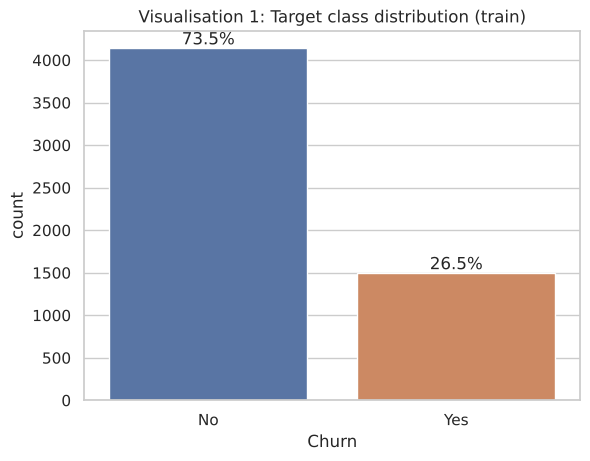

In [9]:
ax = sns.countplot(data=train, x="Churn", hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False)
for p in ax.patches:
    ax.annotate(f"{p.get_height()/len(train):.1%}",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Visualisation 1: Target class distribution (train)")
plt.show()

**Insight:** the classes are **imbalanced** (~73% No vs ~27% Yes). This is why we use stratified splitting/cross-validation, report ROC-AUC/F1 instead of accuracy, and use `class_weight="balanced"` in models (see 1.8).

### Visualisation 2 — Numeric features vs churn

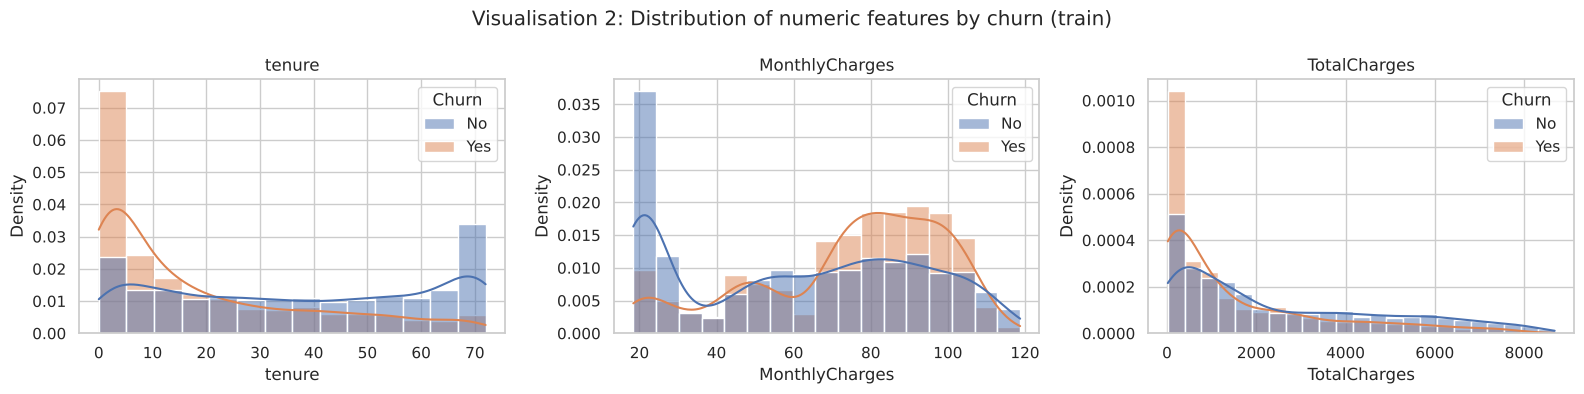

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=train, x=col, hue="Churn", kde=True, stat="density",
                 common_norm=False, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(col)
fig.suptitle("Visualisation 2: Distribution of numeric features by churn (train)")
plt.tight_layout(); plt.show()

**Insights:**
- Churners are concentrated at **low tenure** — most customers who leave do so in their first months.
- Churners tend to have **higher monthly charges** (~70–100).
- `TotalCharges` is strongly right-skewed (it is roughly `tenure × MonthlyCharges`).

### Visualisation 3 — Churn rate by key categorical features

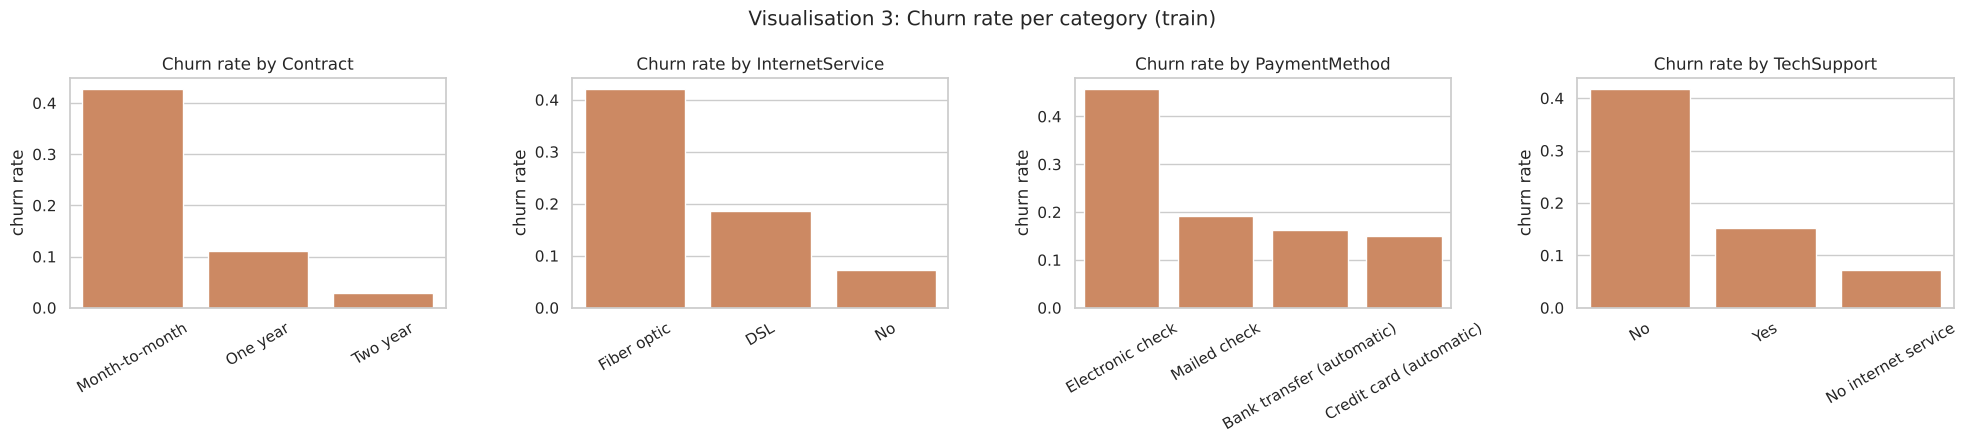

In [11]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, cats):
    rate = (train.assign(c=train["Churn"].eq("Yes"))
                 .groupby(col)["c"].mean().sort_values(ascending=False))
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#DD8452")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("churn rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Visualisation 3: Churn rate per category (train)")
plt.tight_layout(); plt.show()

**Insights:**
- **Month-to-month** contracts churn far more (~43%) than one-year (~11%) or two-year (~3%) contracts — contract type is likely the single strongest predictor.
- **Fiber optic** users churn more than DSL users (possibly price or service quality).
- **Electronic check** payers churn the most; automatic payment methods churn less.
- Customers **without tech support** churn more.

### Visualisation 4 — Correlation between numeric features

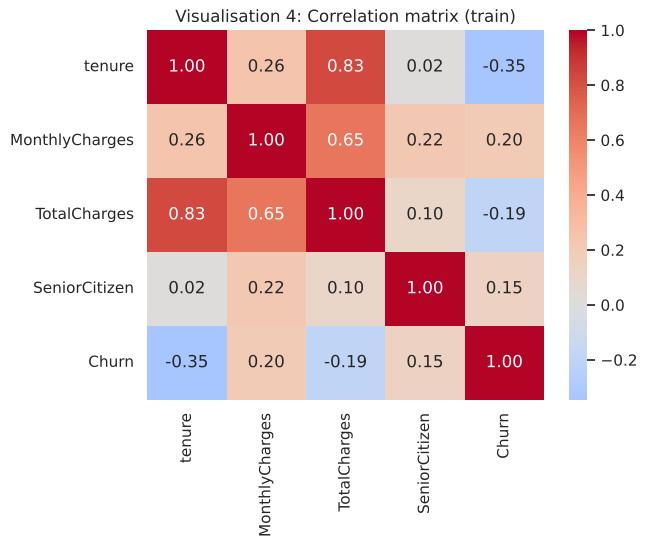

In [12]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
corr = X_train[num_cols].assign(Churn=y_train).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Visualisation 4: Correlation matrix (train)")
plt.show()

**Insight:** `TotalCharges` is highly correlated with `tenure` (~0.83), as expected. This redundancy matters for some models (e.g. multicollinearity in linear models) and is a reason to include a feature-selection step.

### Visualisation 5 — Outlier check (box plots + IQR rule)

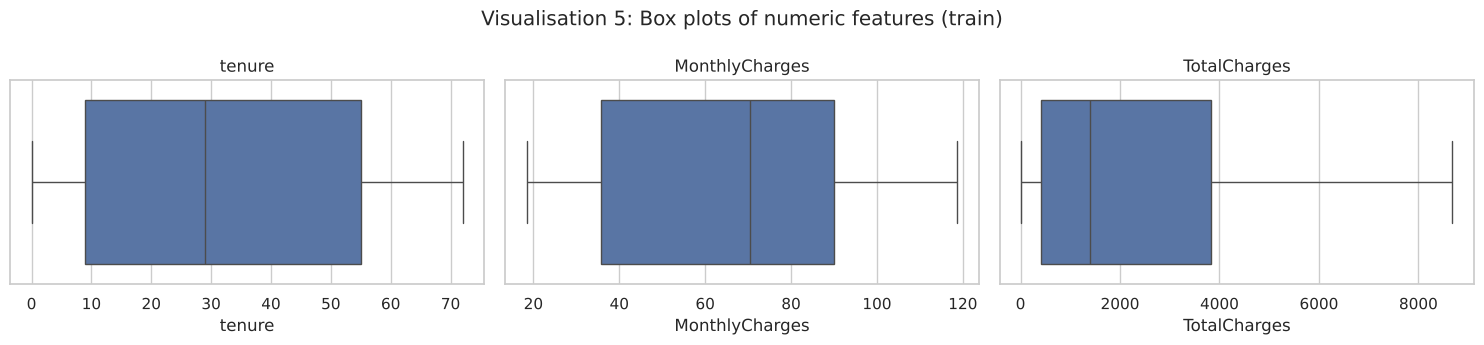

tenure            0
MonthlyCharges    0
TotalCharges      0
Name: IQR outliers (train), dtype: int64

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=X_train[col], ax=ax, color="#4C72B0"); ax.set_title(col)
fig.suptitle("Visualisation 5: Box plots of numeric features (train)")
plt.tight_layout(); plt.show()

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - k*iqr) | (s > q3 + k*iqr)).sum()

pd.Series({c: iqr_outliers(X_train[c].dropna()) for c in ["tenure", "MonthlyCharges", "TotalCharges"]},
          name="IQR outliers (train)")

**Insight:** the raw numeric features have **no IQR outliers** — values are within realistic ranges (tenure 0–72 months, charges ~18–119). We still include an **IQR clipping step in the pipeline** as a safety net: if future/unseen data contains extreme values (e.g. a data-entry error), they'll be capped to bounds **learned from the training data only**. It also handles any outliers in the *engineered* features below.

## 1.6 Feature Construction

We create new features from domain reasoning. They are built by a transformer **inside** the pipeline, so exactly the same logic runs on training data, test data and future production data.

| New feature | Formula | Why |
|---|---|---|
| `AvgChargePerMonth` | `TotalCharges / tenure` (0 if tenure = 0) | average spend over lifetime; differs from current `MonthlyCharges` if the price changed |
| `NumServices` | count of add-on services = "Yes" | customers using more services are more "locked in" |
| `IsNewCustomer` | `tenure <= 6` | EDA showed churn concentrates in the first months |
| `ChargeTenureRatio` | `MonthlyCharges / (tenure + 1)` | high bill + short relationship = high risk |

In [14]:
SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(X):
    """Stateless feature construction: uses only the row itself, learns nothing."""
    X = X.copy()
    X["AvgChargePerMonth"] = np.where(X["tenure"] > 0, X["TotalCharges"] / X["tenure"].replace(0, np.nan), 0.0)
    X["NumServices"] = (X[SERVICE_COLS] == "Yes").sum(axis=1)
    X["IsNewCustomer"] = (X["tenure"] <= 6).astype(int)
    X["ChargeTenureRatio"] = X["MonthlyCharges"] / (X["tenure"] + 1)
    return X

feature_builder = FunctionTransformer(add_features)   # feature_names_out not needed here
add_features(X_train).iloc[:3, -4:]

,AvgChargePerMonth,NumServices,IsNewCustomer,ChargeTenureRatio
3738,48.618571,3,0,1.366667
3151,76.770000,2,0,4.693750
4860,45.411538,3,0,2.896429


## 1.7 Building the Leakage-Free Preprocessing Pipeline

**Key idea:** every step that *learns something from data* (median for imputation, IQR bounds, mean/std for scaling, category list for one-hot encoding, feature scores for selection) is placed in a `Pipeline`. When we call `.fit()` on training data, each step learns its parameters **only from the training data**; `.transform()` on test data then *applies* those learned parameters without re-learning them.

```
raw X ─► FeatureBuilder ─► ColumnTransformer ─┬─ numeric:     median impute ─► IQR clip ─► StandardScaler
                                              └─ categorical: mode impute ─► One-Hot encode
                          ─► SelectKBest (mutual information) ─► model
```

In [15]:
class IQRClipper(BaseEstimator, TransformerMixin):
    """Caps values outside [Q1 - k*IQR, Q3 + k*IQR].
    Bounds are learned in fit() from TRAINING data only, then applied in transform()."""
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_, self.upper_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

In [16]:
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges",
           "AvgChargePerMonth", "NumServices", "ChargeTenureRatio"]
CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "IsNewCustomer",
               "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
               "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
               "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fills the 11 missing TotalCharges
    ("clip",   IQRClipper(k=1.5)),                  # outlier handling
    ("scale",  StandardScaler()),                   # mean 0, std 1
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
])

column_tf = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL),
])

def mi_score(X, y):
    return mutual_info_classif(X, y, random_state=RANDOM_STATE)

preprocessor = Pipeline([
    ("features", feature_builder),
    ("columns",  column_tf),
    ("select",   SelectKBest(score_func=mi_score, k=25)),
])
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f7187874900>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictiona

**Design choices explained**
- **Median imputation** for numbers: robust to skew (`TotalCharges` is skewed). **Most-frequent** for categories.
- **StandardScaler**: puts features on the same scale so distance/gradient-based models (logistic regression, k-NN, neural network in Part 4, k-means in Part 4) are not dominated by large-valued features like `TotalCharges`.
- **One-hot encoding** (not label encoding): categories like `PaymentMethod` have no natural order, so we must not give them numbers 0,1,2,3. `drop="if_binary"` keeps one column for Yes/No features (avoids redundant columns); `handle_unknown="ignore"` prevents crashes if a new category appears in test data.
- **SelectKBest with mutual information**: keeps the 25 most informative of ~45 encoded features. Mutual information captures non-linear relationships too. Because it is inside the pipeline, feature scores are computed on training data only — selecting features on the full dataset is one of the most common forms of leakage.

In [17]:
# Fit on TRAIN only, then apply to both sets
X_train_prep = preprocessor.fit_transform(X_train, y_train)
X_test_prep  = preprocessor.transform(X_test)          # transform only — no re-fitting!

print("Train after preprocessing:", X_train_prep.shape)
print("Test  after preprocessing:", X_test_prep.shape)
print("Missing values left:", np.isnan(X_train_prep).sum(), np.isnan(X_test_prep).sum())

Train after preprocessing: (5634, 25)
Test  after preprocessing: (1409, 25)
Missing values left: 0 0


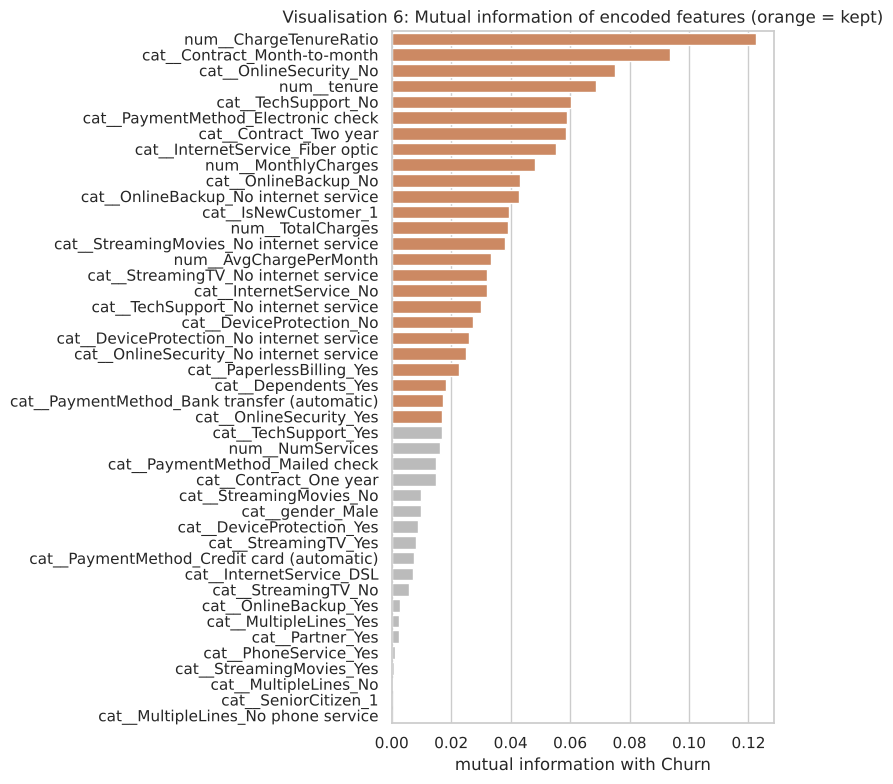

In [18]:
# Which features survived selection, and their mutual-information scores?
all_names = preprocessor.named_steps["columns"].get_feature_names_out()
sel = preprocessor.named_steps["select"]
scores = pd.Series(sel.scores_, index=all_names).sort_values(ascending=False)
kept = scores.index[:25]

plt.figure(figsize=(8, 8))
colors = ["#DD8452" if n in set(all_names[sel.get_support()]) else "#BBBBBB" for n in scores.index]
sns.barplot(x=scores.values, y=scores.index, palette=colors, hue=scores.index, legend=False)
plt.title("Visualisation 6: Mutual information of encoded features (orange = kept)")
plt.xlabel("mutual information with Churn"); plt.ylabel("")
plt.tight_layout(); plt.show()

In [19]:
# Proof that scaling parameters came from TRAIN only:
scaler = preprocessor.named_steps["columns"].named_transformers_["num"].named_steps["scale"]
print("Scaler means learned (train):", np.round(scaler.mean_[:3], 2))
print("Actual train means          :", np.round(X_train[["tenure","MonthlyCharges"]].mean().values, 2))
print("Full-dataset means (NOT used):", np.round(X[["tenure","MonthlyCharges"]].mean().values, 2))

Scaler means learned (train): [  32.49   64.93 2301.32]
Actual train means          : [32.49 64.93]
Full-dataset means (NOT used): [32.37 64.76]


## 1.8 Handling Class Imbalance & Pipeline Sanity Check

We handle imbalance in three leakage-safe ways:
1. **Stratified** train/test split and **stratified** k-fold cross-validation (every fold keeps ~26.5% churners).
2. **`class_weight="balanced"`** in the model: errors on the minority class (churners) cost more during training, so the model doesn't just predict "No".
3. **Metrics** robust to imbalance (ROC-AUC, F1, recall) instead of plain accuracy.

> Oversampling (e.g. SMOTE) is an alternative, but it must **only** be applied to training folds (via `imblearn.pipeline.Pipeline`); oversampling before the split copies synthetic versions of training rows into validation data → leakage.

To verify the pipeline works end-to-end, we attach a simple logistic regression and run **5-fold cross-validation on the training set only**. Because the whole pipeline is re-fitted inside every fold, the validation fold never influences imputation, scaling, encoding or feature selection. (Proper model comparison is Part 2; the test set stays untouched.)

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "roc_auc", "f1", "recall"]

models = {
    "Dummy (always 'No')": DummyClassifier(strategy="most_frequent"),
    "LogReg (unweighted)": LogisticRegression(max_iter=1000),
    "LogReg (class_weight=balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
rows = {}
for name, model in models.items():
    full = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(full, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}
results = pd.DataFrame(rows).T.round(3)
results

,accuracy,roc_auc,f1,recall
Dummy (always 'No'),0.735,0.500,0.000,0.000
LogReg (unweighted),0.805,0.848,0.592,0.532
LogReg (class_weight=balanced),0.753,0.848,0.631,0.796


**Interpretation:**
- The **dummy** model gets ~73% accuracy but **0 F1 / 0 recall** and 0.5 ROC-AUC — proof that accuracy alone is misleading here.
- **Balanced class weights** raise recall on churners substantially (we catch many more of the customers who leave) at the cost of some accuracy — the right trade-off for a retention campaign.
- The ROC-AUC of ~0.84 shows the preprocessed features carry strong signal, giving a solid foundation for Part 2.

## 1.9 Leakage Checklist

| Risk | How we prevented it |
|---|---|
| Test data influencing preprocessing | Split first; all learned steps inside `Pipeline`, fitted on train only |
| Imputation using test statistics | `SimpleImputer` inside pipeline |
| Scaling using test statistics | `StandardScaler` inside pipeline (verified means above) |
| Outlier bounds from full data | Custom `IQRClipper` learns bounds in `fit()` only |
| Feature selection on full data | `SelectKBest` inside pipeline |
| Leakage across CV folds | `cross_validate` re-fits the full pipeline in every fold |
| Identifier columns | `customerID` dropped |
| Target leakage features | None of the inputs are recorded *after* churn happens |

## 1.10 Summary of Part 1
- Framed the task as **binary classification of `Churn`**, evaluated with **ROC-AUC** (primary) and **churn-class F1/recall**.
- Cleaned data types (`TotalCharges`), identified 11 missing values (new customers), dropped the ID column.
- EDA (6 visualisations) showed churn is driven by **short tenure, month-to-month contracts, fiber-optic internet, electronic-check payment and lack of tech support**; classes are imbalanced (~26.5% churn).
- Built a reusable, **leakage-free `preprocessor`** (feature construction → imputation → outlier clipping → scaling / one-hot encoding → mutual-information feature selection) that Parts 2–5 will plug models into.

---
# Part 2 — Supervised Learning Baseline: Naive Bayes vs Decision Tree

**Goal:** train two different kinds of model on the Part 1 pipeline and compare them.

| Model | How it thinks |
|---|---|
| **Gaussian Naive Bayes** | *Probabilistic.* Uses Bayes' theorem: P(churn \| features) ∝ P(churn) × Π P(feature \| churn). "Naive" because it assumes all features are independent of each other given the class. |
| **Decision Tree** | *Rule-based.* Asks a series of yes/no questions (e.g. "Contract = Month-to-month?"), each time choosing the question that best separates churners from non-churners (measured by information gain or Gini). |

Both models are plugged into the **same leakage-free `preprocessor`** from Part 1. The test set is still locked away (used only in Part 5).

## 2.1 Hand-Worked Split: Information Gain and Gini

To show how a decision tree picks a question, we take a **small worked case: 20 customers randomly sampled from the training set** and compare two candidate splits by hand.

In [21]:
sample = X_train.assign(Churn=y_train).sample(20, random_state=7)
print("Churners in sample:", sample["Churn"].sum(), "of", len(sample))
sample[["Contract", "InternetService", "tenure", "MonthlyCharges", "Churn"]]

Churners in sample: 5 of 20


,Contract,InternetService,tenure,MonthlyCharges,Churn
5231,Month-to-month,Fiber optic,16,98.75,1
5732,Month-to-month,Fiber optic,19,87.30,0
5864,Two year,No,47,19.65,0
5719,Two year,No,24,19.70,0
114,Two year,DSL,64,54.60,0
5424,Two year,Fiber optic,65,92.70,0
3747,Month-to-month,DSL,4,58.50,0
1647,Month-to-month,Fiber optic,11,79.50,1
6038,Two year,Fiber optic,70,114.20,1
6909,Month-to-month,DSL,1,53.55,0


In [22]:
display(pd.crosstab(sample["Contract"] == "Month-to-month", sample["Churn"]).rename_axis("Month-to-month?"))
display(pd.crosstab(sample["InternetService"] == "Fiber optic", sample["Churn"]).rename_axis("Fiber optic?"))

Churn,0,1
Month-to-month?,,
False,6,1
True,9,4


Churn,0,1
Fiber optic?,,
False,10,1
True,5,4


### Formulas
- **Entropy:** $H(S) = -\sum_i p_i \log_2 p_i$ — 0 = pure node, 1 = 50/50 mix (for 2 classes)
- **Information gain:** $IG = H(\text{parent}) - \sum_k \frac{|S_k|}{|S|} H(S_k)$
- **Gini impurity:** $G(S) = 1 - \sum_i p_i^2$ — 0 = pure, 0.5 = 50/50 mix

### Parent node (all 20 customers): 15 No, 5 Yes
- $H = -(0.75\log_2 0.75 + 0.25\log_2 0.25) = 0.311 + 0.500 = \mathbf{0.811}$
- $G = 1 - (0.75^2 + 0.25^2) = 1 - 0.625 = \mathbf{0.375}$

### Candidate split A: Contract = Month-to-month?

| Branch | No | Yes | Total | Entropy | Gini |
|---|---|---|---|---|---|
| Yes (month-to-month) | 9 | 4 | 13 | $-(\frac{9}{13}\log_2\frac{9}{13} + \frac{4}{13}\log_2\frac{4}{13}) = 0.890$ | $1-(0.692^2+0.308^2) = 0.426$ |
| No (1- or 2-year) | 6 | 1 | 7 | $-(\frac{6}{7}\log_2\frac{6}{7} + \frac{1}{7}\log_2\frac{1}{7}) = 0.592$ | $1-(0.857^2+0.143^2) = 0.245$ |

- Weighted entropy $= \frac{13}{20}(0.890) + \frac{7}{20}(0.592) = 0.579 + 0.207 = 0.786$
- **IG(A) = 0.811 − 0.786 = 0.025**
- Weighted Gini $= 0.65(0.426) + 0.35(0.245) = 0.363$ → **Gini decrease = 0.375 − 0.363 = 0.012**

### Candidate split B: InternetService = Fiber optic?

| Branch | No | Yes | Total | Entropy | Gini |
|---|---|---|---|---|---|
| Yes (fiber) | 5 | 4 | 9 | $-(\frac{5}{9}\log_2\frac{5}{9} + \frac{4}{9}\log_2\frac{4}{9}) = 0.991$ | $1-(0.556^2+0.444^2) = 0.494$ |
| No (DSL / none) | 10 | 1 | 11 | $-(\frac{10}{11}\log_2\frac{10}{11} + \frac{1}{11}\log_2\frac{1}{11}) = 0.440$ | $1-(0.909^2+0.091^2) = 0.165$ |

- Weighted entropy $= \frac{9}{20}(0.991) + \frac{11}{20}(0.440) = 0.446 + 0.242 = 0.688$
- **IG(B) = 0.811 − 0.688 = 0.124**
- Weighted Gini $= 0.45(0.494) + 0.55(0.165) = 0.313$ → **Gini decrease = 0.375 − 0.313 = 0.062**

### Decision
Split **B (Fiber optic)** wins on both measures (IG 0.124 vs 0.025), so on these 20 customers the tree would ask "Fiber optic?" first. The "No" branch (10 No / 1 Yes) is almost pure.

> **Note:** on the full training set, `Contract` is the stronger feature (Part 1 EDA). A 20-row sample can rank features differently — this is exactly why trees trained on small data are unstable and can overfit.

In [23]:
# Verify the hand calculation with code
def entropy(y):
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def gini(y):
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - (p ** 2).sum()

def split_scores(mask, y):
    y = y.values; n = len(y)
    l, r = y[mask.values], y[~mask.values]
    ig = entropy(y) - (len(l)/n * entropy(l) + len(r)/n * entropy(r))
    gd = gini(y)    - (len(l)/n * gini(l)    + len(r)/n * gini(r))
    return round(ig, 3), round(gd, 3)

ys = sample["Churn"]
print("Parent: entropy = %.3f, gini = %.3f" % (entropy(ys.values), gini(ys.values)))
print("A  Contract = Month-to-month -> (IG, Gini decrease) =", split_scores(sample["Contract"] == "Month-to-month", ys))
print("B  InternetService = Fiber   -> (IG, Gini decrease) =", split_scores(sample["InternetService"] == "Fiber optic", ys))

Parent: entropy = 0.811, gini = 0.375
A  Contract = Month-to-month -> (IG, Gini decrease) = (np.float64(0.025), np.float64(0.012))
B  InternetService = Fiber   -> (IG, Gini decrease) = (np.float64(0.124), np.float64(0.062))


## 2.2 Training the Models

- **Gaussian NB:** works on the scaled numeric + one-hot features from the pipeline. It has no `class_weight` option, so it uses the natural class priors (~73/27).
- **Decision Tree:** `max_depth=5` keeps it small and readable (an unlimited tree memorises the training data — shown in 2.4). `class_weight="balanced"` handles the imbalance, as in Part 1. `criterion="entropy"` uses information gain, matching 2.1.

In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

nb_model = Pipeline([("prep", preprocessor), ("model", GaussianNB())])
dt_model = Pipeline([("prep", preprocessor),
                     ("model", DecisionTreeClassifier(max_depth=5, criterion="entropy",
                                                      class_weight="balanced",
                                                      random_state=RANDOM_STATE))])
models2 = {"Gaussian Naive Bayes": nb_model, "Decision Tree (depth 5)": dt_model}

## 2.3 Evaluation with Stratified 5-Fold Cross-Validation

**Why cross-validation?** One train/validation split can be lucky or unlucky. 5-fold CV splits the training set into 5 parts, trains on 4 and tests on the 5th, five times, then averages. **Stratified** keeps ~26.5% churners in every fold. The whole pipeline is re-fitted inside each fold, so there is no leakage.

**Metrics** (chosen in Part 1): **ROC-AUC** (main), **F1** and **recall** for the churn class, plus precision and accuracy for context.

In [25]:
scoring = ["roc_auc", "f1", "recall", "precision", "accuracy"]
cv_rows = {}
for name, m in models2.items():
    res = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {s: f"{res['test_'+s].mean():.3f} ± {res['test_'+s].std():.3f}" for s in scoring}
cv_table = pd.DataFrame(cv_rows).T
cv_table

,roc_auc,f1,recall,precision,accuracy
Gaussian Naive Bayes,0.825 ± 0.011,0.595 ± 0.014,0.853 ± 0.024,0.457 ± 0.016,0.692 ± 0.018
Decision Tree (depth 5),0.830 ± 0.012,0.612 ± 0.013,0.809 ± 0.041,0.493 ± 0.014,0.728 ± 0.012


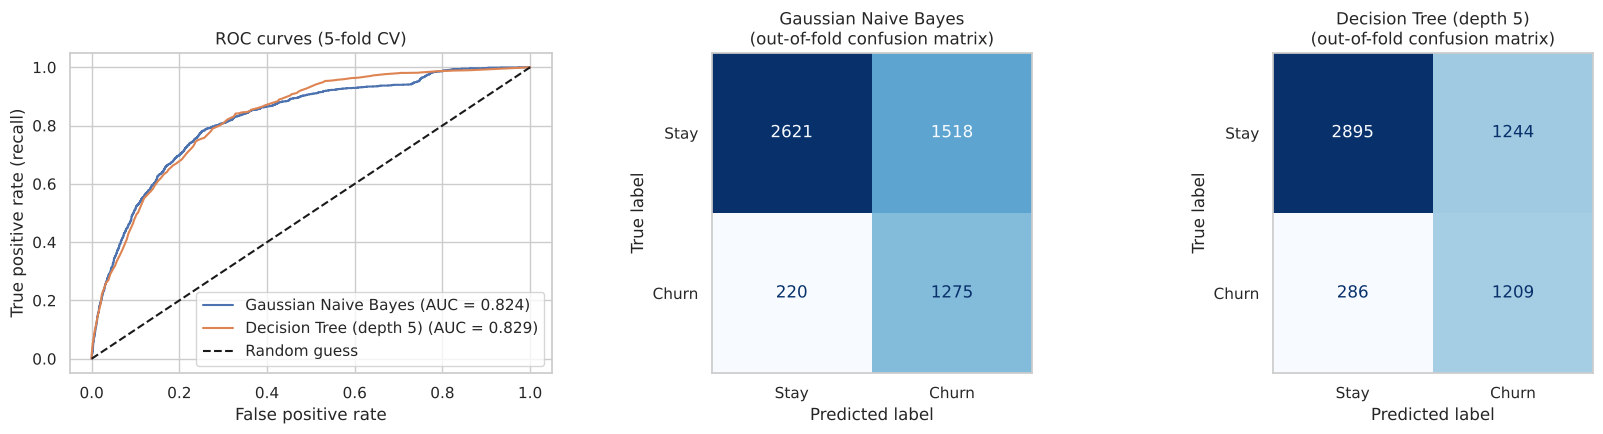

In [26]:
# Out-of-fold predictions: every training row is predicted by a model that did NOT see it
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for i, (name, m) in enumerate(models2.items()):
    proba = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_train, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_train, proba):.3f})")
    ConfusionMatrixDisplay(confusion_matrix(y_train, (proba >= 0.5).astype(int)),
                           display_labels=["Stay", "Churn"]).plot(ax=axes[i+1], colorbar=False, cmap="Blues")
    axes[i+1].set_title(f"{name}\n(out-of-fold confusion matrix)"); axes[i+1].grid(False)
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves (5-fold CV)"); axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 2.4 Looking Inside the Models
In the tree plot, the root shows entropy = 1.0 and value = [0.5, 0.5]. That's because `class_weight="balanced"` re-weights the classes so they count equally. It doesn't mean the data is really 50/50.

In [27]:
# Overfitting check: training score vs cross-validated score
rows = {}
for depth in [5, None]:
    m = Pipeline([("prep", preprocessor),
                  ("model", DecisionTreeClassifier(max_depth=depth, criterion="entropy",
                                                   class_weight="balanced", random_state=RANDOM_STATE))])
    res = cross_validate(m, X_train, y_train, cv=cv, scoring="roc_auc", return_train_score=True)
    rows[f"max_depth={depth}"] = {"train ROC-AUC": res["train_score"].mean(), "CV ROC-AUC": res["test_score"].mean()}
pd.DataFrame(rows).T.round(3)

,train ROC-AUC,CV ROC-AUC
max_depth=5,0.856,0.830
max_depth=None,1.000,0.662


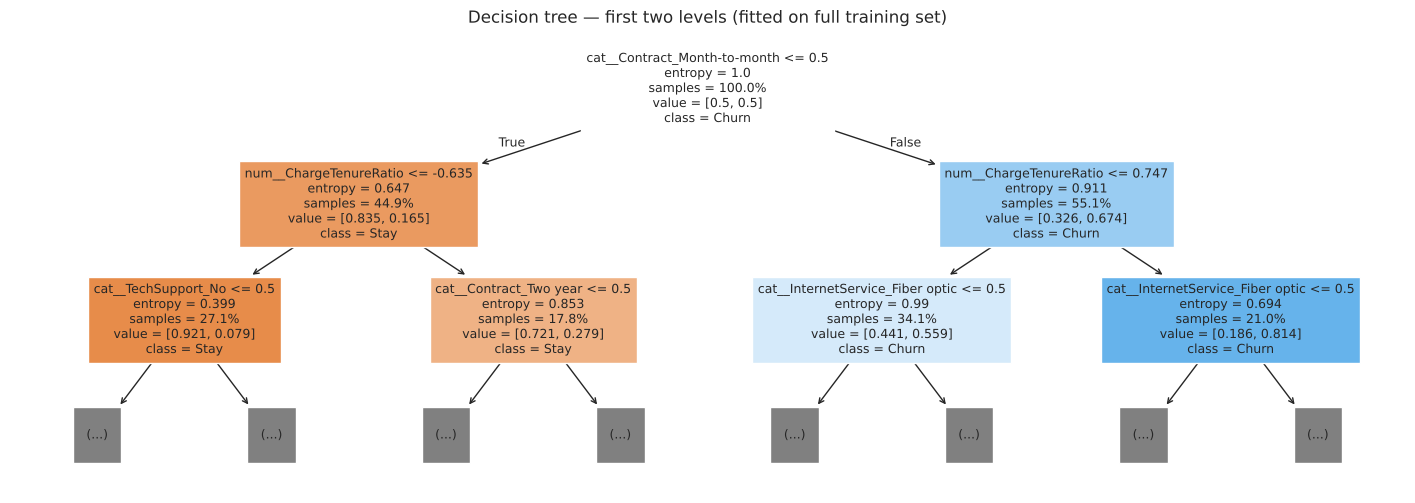

,importance
cat__Contract_Month-to-month,0.541
num__ChargeTenureRatio,0.172
cat__InternetService_Fiber optic,0.105
num__TotalCharges,0.045
num__MonthlyCharges,0.032
cat__PaymentMethod_Electronic check,0.028
cat__TechSupport_No,0.023
cat__Contract_Two year,0.019


In [28]:
# Top of the fitted depth-5 tree (first 2 levels shown for readability)
dt_model.fit(X_train, y_train)
names = preprocessor.named_steps["columns"].get_feature_names_out()[preprocessor.named_steps["select"].get_support()]
plt.figure(figsize=(18, 6))
plot_tree(dt_model.named_steps["model"], feature_names=names, class_names=["Stay", "Churn"],
          max_depth=2, filled=True, impurity=True, proportion=True, fontsize=9)
plt.title("Decision tree — first two levels (fitted on full training set)")
plt.show()

imp = pd.Series(dt_model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(8)
imp.round(3).to_frame("importance")

In [29]:
# Naive Bayes independence check: how correlated are some of the features it assumes independent?
Xt = pd.DataFrame(preprocessor.fit_transform(X_train, y_train), columns=names)
cols = [c for c in ["num__tenure", "num__TotalCharges", "num__MonthlyCharges", "num__AvgChargePerMonth"] if c in Xt]
Xt[cols].corr().round(2)

,num__tenure,num__TotalCharges,num__MonthlyCharges,num__AvgChargePerMonth
num__tenure,1.00,0.83,0.26,0.26
num__TotalCharges,0.83,1.00,0.65,0.65
num__MonthlyCharges,0.26,0.65,1.00,0.99
num__AvgChargePerMonth,0.26,0.65,0.99,1.00


## 2.5 Comparison Write-Up

| (5-fold CV, mean ± std) | ROC-AUC | F1 | Recall | Precision | Accuracy |
|---|---|---|---|---|---|
| Gaussian Naive Bayes | 0.825 ± 0.011 | 0.595 ± 0.014 | **0.853** ± 0.024 | 0.457 ± 0.016 | 0.692 ± 0.018 |
| Decision Tree (depth 5) | **0.830** ± 0.012 | **0.612** ± 0.013 | 0.809 ± 0.041 | **0.493** ± 0.014 | **0.728** ± 0.012 |

**Which is better?** The **decision tree** is better overall, but only slightly. It has the higher ROC-AUC (0.830 vs 0.825) and F1 (0.612 vs 0.595), plus better precision and accuracy. The ROC-AUC gap is within one standard deviation, so on ranking ability the two models are close. The clearer difference is in *how* they make mistakes. Naive Bayes catches a few more churners (recall 0.85 vs 0.81), but it raises far more false alarms (precision 0.46 vs 0.49), so more retention offers would go to customers who were never going to leave.

**Why does the tree do better?**
1. **The "naive" independence assumption is broken.** Section 2.4 shows `MonthlyCharges` and `AvgChargePerMonth` have a correlation of **0.99**, and `tenure` and `TotalCharges` 0.83. Naive Bayes treats these as independent pieces of evidence, so it counts the same information several times and becomes overconfident. That is why it labels too many customers as churners.
2. **The Gaussian assumption fits poorly.** Gaussian NB models each feature as a bell curve, but tenure and charges are skewed and the one-hot columns are only 0/1.
3. **The tree captures interactions.** Churn depends on *combinations* of factors. The tree's top split is `Contract = Month-to-month` (54% of its feature importance), followed by `ChargeTenureRatio` (our Part 1 engineered feature) and `Fiber optic`. Nested rules like "month-to-month **and** high charge per month of tenure" come naturally to a tree but not to NB.
4. **Depth control matters.** An unlimited tree scores 1.000 ROC-AUC on training data but only **0.662** in CV, which is severe overfitting. Limiting depth to 5 brings the training score (0.856) close to the CV score (0.830), so the model generalises.

**Why NB still does reasonably well:** with only 25 selected features and a strong signal in a few of them (contract, tenure, charges), even a simple probabilistic model ranks customers well. It is also much faster and needs no tuning, so it is a sensible baseline.

**Limitations and next step:** a single tree is unstable. The 20-customer worked example chose `InternetService` as the first split, while the full data chooses `Contract`. In Part 3 we will use ensembles (Random Forest, Gradient Boosting) that average many trees to reduce this variance, and tune `max_depth` and other hyperparameters properly instead of fixing them by hand.